# Single-film indentation: elastic modulus and hardness

This notebook analyzes the bundled 500 nm SiO₂ film on a Si substrate using `MTS_1film_SiO2_Si_CSM-2nm.xls`. It compares NIMS's bilayer Doerner–Nix elastic modulus fit with Saha- and Mercier-style film-hardness estimates. The workbook's Oliver–Pharr (OP) modulus and hardness columns are plotted as independent instrument-reported checks.

**Scope:** NIMS's bilayer “plastic” path estimates hardness from indentation load/stiffness and an elastic modulus; it is not a nonlinear plastic finite-element constitutive model. The notebook follows the NIMS bilayer equations but uses dimensionally consistent GPa for the indenter correction, so the hardness estimates are not bit-for-bit MATLAB GUI results. The source GUI's model labels and some numeric dispatch branches also differ; this notebook names the equations it evaluates.

Run from the repository root or this notebook's folder. Requirements: Python 3, NumPy, SciPy, Matplotlib, and `xlrd` (install with `python -m pip install xlrd` to read legacy `.xls`). Lengths are nm, load mN, stiffness mN/nm, and moduli/hardness GPa. The film/substrate properties and calibration below are assumptions to review before interpreting results.

In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xlrd
from scipy.optimize import least_squares

cwd = Path.cwd().resolve()
root = next((p for p in (cwd, *cwd.parents)
             if (p / 'data_indentation').is_dir()
             and (p / 'matlab_code').is_dir()), None)
if root is None:
    raise FileNotFoundError('Start Jupyter in the NIMS repository or one of its subdirectories.')
data_file = root / 'data_indentation' / 'MTS_1film_SiO2_Si_CSM-2nm.xls'
if not data_file.is_file():
    raise FileNotFoundError(f'Indentation workbook not found: {data_file}')
print('Repository:', root)

Repository: C:\github\NIMS


## Specimen, calibration, and loading segment

The loading data are extracted from the first sheet up to the first hold/unload marker, matching the NIMS spreadsheet import convention. The example uses a 500 nm film, Si substrate at 165 GPa, and a SiO₂ Poisson ratio of 0.18. NIMS's bundled `Berko_Example` area function, CSM correction, Berkovich beta, and Loubet contact-depth factor are exposed below; replace them with the calibration used for the experiment.

In [16]:
film = {'name': 'SiO2', 'thickness_nm': 500.0, 'nu': 0.18}
substrate = {'name': 'Si', 'E_GPa': 165.0, 'nu': 0.28}
film_initial_young_GPa = 60.0
indenter_E_GPa, indenter_nu = 1070.0, 0.07
beta = 1.034
area_coefficients = [23.58, 1173.55, -4230.85, 2172.3, 0, 0, 0, 0, 0]
area_powers = [2, 1, 1/2, 1/4, 1/8, 1/16, 1/32, 1/64, 1/128]
tip_defect_nm = 0.0
loubet_alpha = 1.24
apply_csm_correction = True
csm_k, csm_m = 0.757, 1.38
thickness_correction_factor = 0.3
alpha_bounds = (0.0, 0.5)

book = xlrd.open_workbook(str(data_file), on_demand=True)
sheet = book.sheet_by_index(0)
headers = [str(value).strip() for value in sheet.row_values(0)]
segment_markers = {'Hold Segment Type', 'Unload From Peak Segment Type'}
boundary = next((row for row in range(2, sheet.nrows)
                 if sheet.cell_value(row, 0) in segment_markers), None)
if boundary is None:
    raise ValueError('No hold or unload marker found after the loading segment.')

measurement_names = [
    'Displacement Into Surface',
    'STANDARD DEVIATION (Displacement Into Surface)',
    'Load On Sample',
    'STANDARD DEVIATION (Load On Sample)',
    'Harmonic Contact Stiffness',
    'STANDARD DEVIATION (Harmonic Contact Stiffness)',
    'OP_Hardness',
    'OP_Modulus',
]
missing = [name for name in measurement_names if name not in headers]
if missing:
    raise ValueError(f'Workbook is missing required columns: {missing}')
columns = [headers.index(name) for name in measurement_names]
raw = np.asarray([
    [sheet.cell_value(row, column) for column in columns]
    for row in range(2, boundary)
], dtype=float)
if raw.ndim != 2 or raw.shape[0] < 4 or not np.isfinite(raw).all():
    raise ValueError('Expected at least four finite loading rows and OP reference values.')
depth, depth_sd, load, load_sd, stiffness_N_m, stiffness_sd, op_hardness, op_young = raw.T
stiffness = stiffness_N_m * 1e-6  # N/m -> mN/nm
if np.any(load <= 0) or np.any(stiffness <= 0) or np.any(depth_sd <= 0):
    raise ValueError('Loading force, stiffness, and displacement SD must be positive.')

if apply_csm_correction:
    peak_load = load.max()
    radicand = 1 - 2 * np.sqrt(2) * depth_sd * stiffness / peak_load
    if np.any(radicand < 0):
        raise ValueError('CSM correction is not real for the selected loading data.')
    stiffness = ((1 / np.sqrt(2 * np.pi)) * (1 / csm_k) ** (1 / csm_m)
                 * (1 - radicand ** (1 / csm_m)) * peak_load / depth_sd)
    depth = depth + np.sqrt(2) * depth_sd
    load = load + np.sqrt(2) * load_sd
if np.any(~np.isfinite(stiffness) | (stiffness <= 0)):
    raise ValueError('Corrected stiffness must be finite and positive.')

contact_depth = loubet_alpha * (depth + tip_defect_nm - load / stiffness)
area = sum(c * contact_depth ** power
           for c, power in zip(area_coefficients, area_powers))
corrected_film_thickness = film['thickness_nm'] - thickness_correction_factor * contact_depth
valid = (np.isfinite(contact_depth) & (contact_depth > 0)
         & np.isfinite(area) & (area > 0)
         & (corrected_film_thickness > 0))
excluded_count = int(np.count_nonzero(~valid))
if np.count_nonzero(valid) < 4:
    raise ValueError('Fewer than four physical points remain after contact-area checks.')
depth, contact_depth, load, stiffness, area = [
    values[valid] for values in (depth, contact_depth, load, stiffness, area)
]
op_hardness, op_young = op_hardness[valid], op_young[valid]
sample_hardness = 1e6 * load / area
contact_radius = np.sqrt(area / np.pi)
print(f'{len(depth)} physical loading points retained; excluded {excluded_count}.')
print(f'Contact depth: {contact_depth.min():.1f}–{contact_depth.max():.1f} nm')

60 physical loading points retained; excluded 1.
Contact depth: 5.0–1649.6 nm


## Elastic bilayer response: Doerner–Nix fit

NIMS's bilayer Doerner–Nix relation mixes film and substrate reduced moduli exponentially: $1/E' = (1-e^{-\alpha x})/E'_f + e^{-\alpha x}/E'_s$, with $x=t_{corr}/h_c$. The fitted parameters are the film reduced modulus and dimensionless transition parameter $\alpha$ (NIMS bounds it from 0 to 0.5). The plotted OP modulus is converted to reduced modulus using the assumed specimen Poisson ratio and is shown only as a cross-check.

In [17]:
def reduced_modulus(young_GPa, poisson):
    if not np.isfinite(young_GPa) or young_GPa <= 0 or not -1 < poisson < 0.5:
        raise ValueError('Young modulus must be positive and Poisson ratio must be between -1 and 0.5.')
    return young_GPa / (1 - poisson ** 2)

substrate_reduced_GPa = reduced_modulus(substrate['E_GPa'], substrate['nu'])
film_thickness_corrected = film['thickness_nm'] - thickness_correction_factor * contact_depth
transition_coordinate = film_thickness_corrected / contact_depth
if np.any(~np.isfinite(transition_coordinate) | (transition_coordinate <= 0)):
    raise ValueError('Doerner–Nix transition coordinate must be finite and positive.')

# NIMS's elastic path uses the configured indenter modulus in GPa and the legacy nu_i**2 reduction.
indenter_reduced_legacy_GPa = reduced_modulus(indenter_E_GPa, indenter_nu ** 2)
effective_modulus = np.sqrt(np.pi) * 1e6 * stiffness / (2 * beta * np.sqrt(area))
sample_compliance = 1 / effective_modulus - 1 / indenter_reduced_legacy_GPa
if np.any(~np.isfinite(sample_compliance) | (sample_compliance <= 0)):
    raise ValueError('Invalid sample reduced modulus; review the area calibration and CSM correction.')
sample_reduced_GPa = 1 / sample_compliance

def doerner_nix_reduced(params, coordinate):
    film_reduced, alpha = params
    film_weight = 1 - np.exp(-alpha * coordinate)
    substrate_weight = 1 - film_weight
    return 1 / (film_weight / film_reduced + substrate_weight / substrate_reduced_GPa)

initial = [reduced_modulus(film_initial_young_GPa, film['nu']), 0.25]
fit = least_squares(
    lambda params: doerner_nix_reduced(params, transition_coordinate) - sample_reduced_GPa,
    initial,
    bounds=([1e-6, alpha_bounds[0]], [1000.0, alpha_bounds[1]]),
)
if not fit.success:
    raise RuntimeError(f'Doerner–Nix fit failed: {fit.message}')
fitted_film_reduced_GPa, fitted_alpha = fit.x
fitted_film_young_GPa = fitted_film_reduced_GPa * (1 - film['nu'] ** 2)
composite_fitted_GPa = doerner_nix_reduced(fit.x, transition_coordinate)
fit_rmse_GPa = float(np.sqrt(np.mean(fit.fun ** 2)))

exp_term = np.exp(-fitted_alpha * transition_coordinate)
film_inverse_compliance = (1 / sample_reduced_GPa - exp_term / substrate_reduced_GPa) / (1 - exp_term)
valid_film_estimate = np.isfinite(film_inverse_compliance) & (film_inverse_compliance > 0)
film_reduced_pointwise_GPa = np.full_like(sample_reduced_GPa, np.nan)
film_reduced_pointwise_GPa[valid_film_estimate] = 1 / film_inverse_compliance[valid_film_estimate]
if not np.any(valid_film_estimate):
    raise ValueError('No physical pointwise film-modulus estimates remain.')
print(f'Fitted SiO2 Young modulus: {fitted_film_young_GPa:.2f} GPa')
print(f'Fitted alpha: {fitted_alpha:.4f}; reduced film modulus: {fitted_film_reduced_GPa:.2f} GPa')
print(f'Fit RMSE: {fit_rmse_GPa:.2f} GPa')
if np.isclose(fitted_alpha, alpha_bounds[1], rtol=0, atol=1e-5):
    print('Warning: alpha reached its upper bound; inspect calibration, fit range, and model suitability.')

Fitted SiO2 Young modulus: 89.28 GPa
Fitted alpha: 0.5000; reduced film modulus: 92.27 GPa
Fit RMSE: 25.98 GPa


## Hardness workflow: Saha and Mercier estimates

The Saha relation uses the fitted composite reduced modulus; the Mercier relation uses the pointwise film reduced modulus. Both calculate hardness from load and contact stiffness. The reported composite $P/A$ and workbook OP hardness provide independent comparisons. They are apparent indentation hardness values, not yield stresses or a plastic stress–strain law.

In [18]:
indenter_reduced_GPa = reduced_modulus(indenter_E_GPa, indenter_nu)
effective_for_saha = 1 / (1 / composite_fitted_GPa + 1 / indenter_reduced_GPa)
effective_for_mercier = 1 / (1 / film_reduced_pointwise_GPa + 1 / indenter_reduced_GPa)
hardness_factor = beta ** 2 * (4 / np.pi) * load / (1e6 * stiffness ** 2)
hardness_saha_GPa = hardness_factor * effective_for_saha ** 2
hardness_mercier_GPa = hardness_factor * effective_for_mercier ** 2
if not np.any(np.isfinite(hardness_saha_GPa)) or not np.any(np.isfinite(hardness_mercier_GPa)):
    raise ValueError('Hardness estimates are non-finite; review model inputs and units.')
print(f'Mean composite hardness P/A: {np.mean(sample_hardness):.2f} GPa')
print(f'Mean workbook OP hardness: {np.mean(op_hardness):.2f} GPa')
print(f'Mean Saha-style film estimate: {np.nanmean(hardness_saha_GPa):.2f} GPa')
print(f'Mean Mercier-style film estimate: {np.nanmean(hardness_mercier_GPa):.2f} GPa')

Mean composite hardness P/A: 11.22 GPa
Mean workbook OP hardness: 10.78 GPa
Mean Saha-style film estimate: 11.07 GPa
Mean Mercier-style film estimate: 7.13 GPa


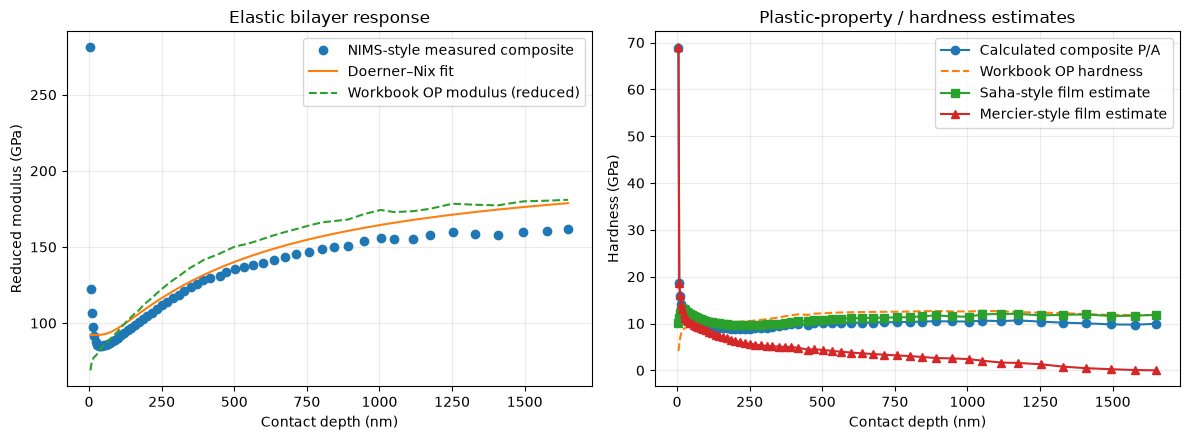

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(contact_depth, sample_reduced_GPa, 'o', label='NIMS-style measured composite')
axes[0].plot(contact_depth, composite_fitted_GPa, '-', label='Doerner–Nix fit')
axes[0].plot(contact_depth, op_young / (1 - film['nu'] ** 2), '--', label='Workbook OP modulus (reduced)')
axes[0].set(xlabel='Contact depth (nm)', ylabel='Reduced modulus (GPa)', title='Elastic bilayer response')
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].plot(contact_depth, sample_hardness, 'o-', label='Calculated composite P/A')
axes[1].plot(contact_depth, op_hardness, '--', label='Workbook OP hardness')
axes[1].plot(contact_depth, hardness_saha_GPa, 's-', label='Saha-style film estimate')
axes[1].plot(contact_depth, hardness_mercier_GPa, '^-', label='Mercier-style film estimate')
axes[1].set(xlabel='Contact depth (nm)', ylabel='Hardness (GPa)', title='Plastic-property / hardness estimates')
axes[1].legend()
axes[1].grid(alpha=0.25)
fig.tight_layout()
plt.show()

In [20]:
summary = [
    ('Elastic fit', 'SiO2 Young modulus', fitted_film_young_GPa),
    ('Elastic fit', 'Doerner–Nix alpha', fitted_alpha),
    ('Elastic fit', 'Composite-modulus RMSE', fit_rmse_GPa),
    ('Plastic estimate', 'Composite hardness P/A', float(np.mean(sample_hardness))),
    ('Instrument reference', 'Workbook OP hardness', float(np.mean(op_hardness))),
    ('Plastic estimate', 'Saha-style film hardness', float(np.nanmean(hardness_saha_GPa))),
    ('Plastic estimate', 'Mercier-style film hardness', float(np.nanmean(hardness_mercier_GPa))),
]
print(f"{'Workflow':<22} {'Quantity':<31} {'Mean':>10}")
print('-' * 67)
for workflow, quantity, value in summary:
    print(f'{workflow:<22} {quantity:<31} {value:>10.3f}')
assert np.isfinite(fitted_film_young_GPa) and fitted_film_young_GPa > 0
assert np.all(np.isfinite(composite_fitted_GPa) & (composite_fitted_GPa > 0))
assert np.all(np.isfinite(sample_hardness) & (sample_hardness > 0))
print('\nSanity checks passed: fitted modulus, composite response, and hardness are finite and positive.')

Workflow               Quantity                              Mean
-------------------------------------------------------------------
Elastic fit            SiO2 Young modulus                  89.281
Elastic fit            Doerner–Nix alpha                    0.500
Elastic fit            Composite-modulus RMSE              25.980
Plastic estimate       Composite hardness P/A              11.218
Instrument reference   Workbook OP hardness                10.782
Plastic estimate       Saha-style film hardness            11.073
Plastic estimate       Mercier-style film hardness          7.130

Sanity checks passed: fitted modulus, composite response, and hardness are finite and positive.


## Compare all implemented bilayer models

The next cell evaluates all 13 elastic bilayer equations listed by NIMS on a common depth subset and summarizes same-domain RMSE, MAE, R², and AICc. It also compares the implemented Kao–Byrne and Bhattacharya–Nix hardness fits, plus Saha/Mercier estimates using each elastic model's fitted moduli. Substrate hardness for the curve fits is estimated from the deepest data points only as a transparent placeholder; replace it with an independent substrate measurement. NIMS lists Han et al., but no corresponding Han implementation is present in this repository. Statistics are unweighted diagnostics, not uncertainty estimates.

Elastic comparison: 13 of 13 models fitted; common points n=40.
Model                            Ef (GPa)   k      RMSE       MAE       R2       AICc
Korsunsky–Constantinescu           289.00   4     16.44     13.98    0.739     233.14
Doerner–Nix                         90.88   2     30.75     12.05    0.088     278.38
Mencik linear                       94.56   2     30.87     13.69    0.080     278.71
Mencik reciprocal exponential       94.69   2     30.93     13.97    0.077     278.86
Mencik exponential                  95.21   2     31.03     14.50    0.071     279.12
Bec et al.                          68.00   1     36.39     17.99   -0.278     289.65
Jung et al.                         76.14   1     36.92     21.03   -0.316     290.82
Perriot–Barthel                     69.97   2     36.01     17.91   -0.251     291.02
Doerner–Nix / Chen                  69.66   2     36.08     17.22   -0.256     291.17
Doerner–Nix / King                  70.73   2     37.40     20.64   -0.350  

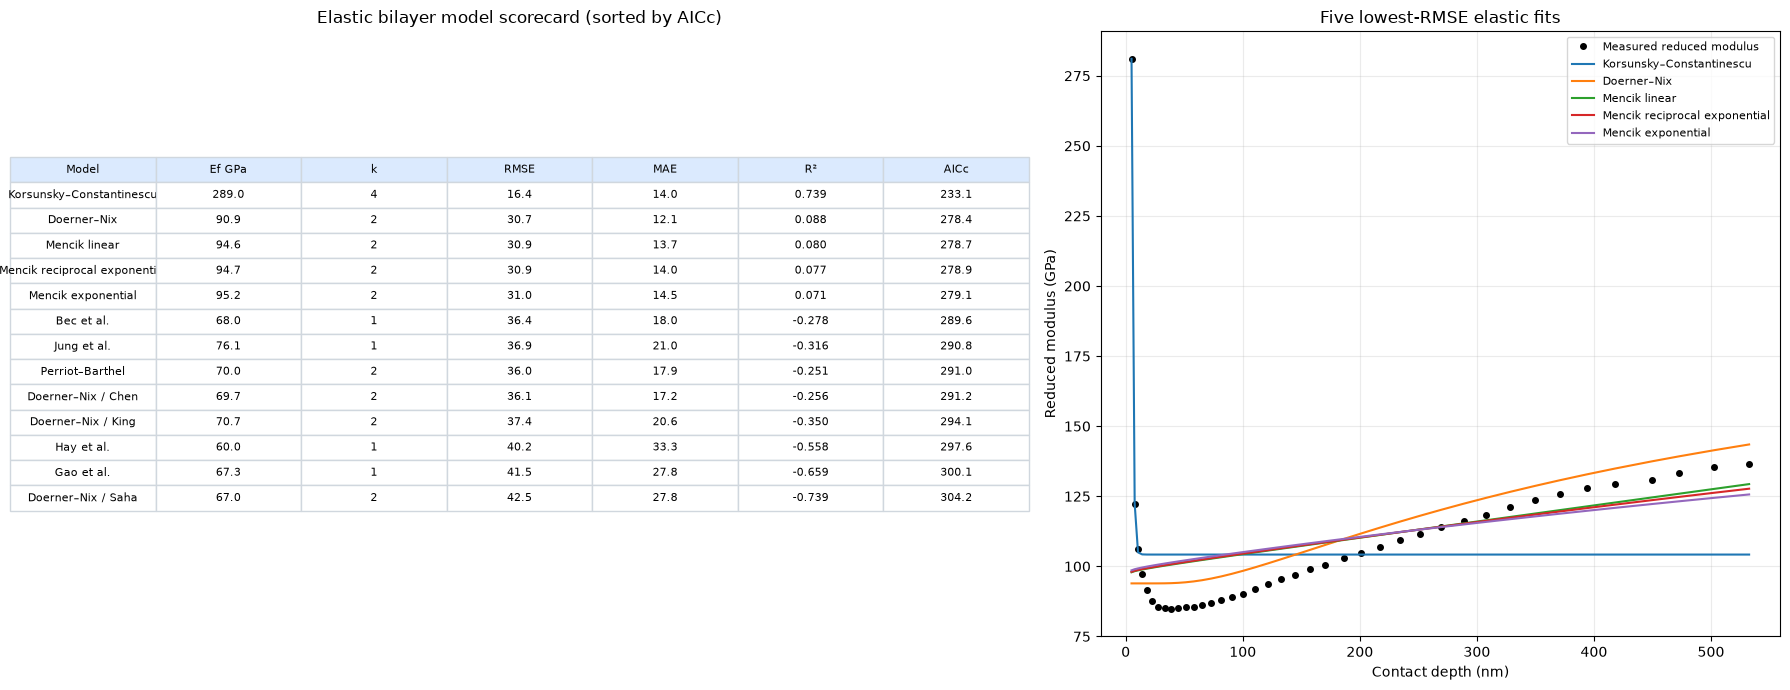


Hardness curve fits; provisional substrate hardness anchor = 10.42 GPa.
Model                           Hfilm (GPa)   k      RMSE       MAE       R2       AICc
Kao–Byrne                             12.30   1      4.60      2.55    0.641     185.16
Bhattacharya–Nix (n=2)                12.22   2      7.60      2.59    0.017     247.66
Bhattacharya–Nix (n=1)                12.42   2      7.59      2.68    0.021     247.43

Saha/Mercier depthwise film-hardness summaries (spread is across indentation depths, not a confidence interval):
Elastic model                  Method         Mean        SD       P10       P90
Korsunsky–Constantinescu       Saha          12.41      9.89      6.71     16.15
Korsunsky–Constantinescu       Mercier       65.85     21.43     40.59     94.17
Doerner–Nix                    Saha          11.12      1.16      9.98     12.87
Doerner–Nix                    Mercier        8.99      2.93      5.54     12.86
Mencik linear                  Saha          11.34      

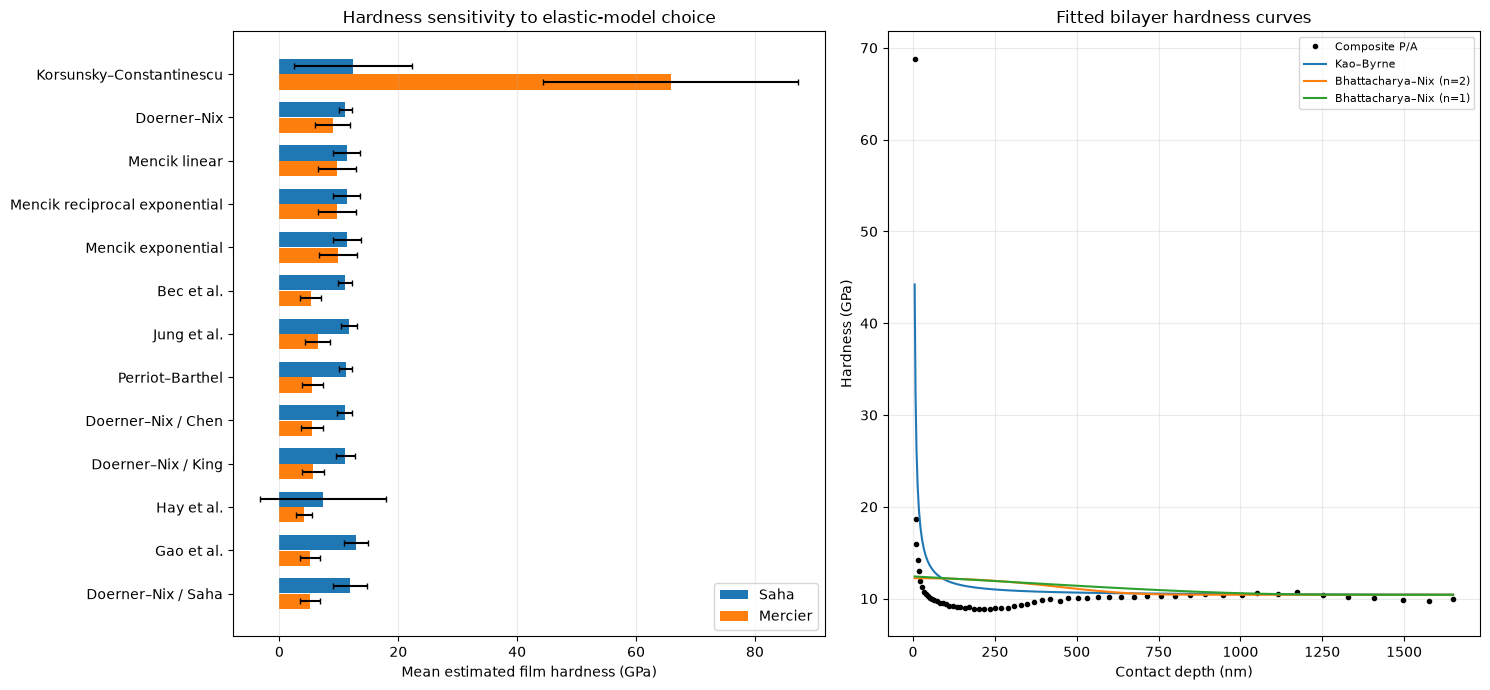


Not implemented: Han et al. hardness equation (GUI label only; no model_han*.m source found).
AICc assumes independent, equal-variance residuals; use it as a relative in-sample diagnostic only.


In [21]:
from scipy.optimize import least_squares

# Restrict all elastic equations to a shared range where the OP depth is below film thickness.
op_contact_depth = depth + tip_defect_nm - 0.75 * load / stiffness
elastic_mask = np.isfinite(op_contact_depth) & (op_contact_depth > 0) & (op_contact_depth < film['thickness_nm'])
if np.count_nonzero(elastic_mask) < 6:
    raise ValueError('Too few shared-depth points remain for a multi-parameter model comparison.')
hc_fit = contact_depth[elastic_mask]
h_fit = depth[elastic_mask]
a_fit = contact_radius[elastic_mask]
tc_fit = film_thickness_corrected[elastic_mask]
y_fit = sample_reduced_GPa[elastic_mask]
hc_op_fit = op_contact_depth[elastic_mask]
substrate_red = substrate_reduced_GPa
film_nu = film['nu']
substrate_nu = substrate['nu']
film_t = film['thickness_nm']
x_dn = tc_fit / hc_fit
x_contact_radius = tc_fit / a_fit
x_saha = (film_t - hc_op_fit) / a_fit
x_jung = hc_fit / tc_fit
x_mencik = a_fit / film_t
x_korsunsky = h_fit / tc_fit

def dn_curve(params, coordinate, exponent=1.0):
    film_red, alpha = params
    transition = np.exp(-alpha * coordinate ** exponent)
    return 1 / ((1 - transition) / film_red + transition / substrate_red)

def gao_weights(x):
    phi1 = (2 / np.pi) * np.arctan(x) + (x / np.pi) * np.log((1 + x ** 2) / x ** 2)
    nu_composite = 1 - ((1 - substrate_nu) * (1 - film_nu) /
                        (1 - (1 - phi1) * film_nu - phi1 * substrate_nu))
    phi0 = ((2 / np.pi) * np.arctan(x) +
            (1 / (2 * np.pi * (1 - nu_composite))) *
            ((1 - 2 * nu_composite) * x * np.log(1 + (1 / x) ** 2) - x / (1 + x ** 2)))
    return phi0, nu_composite

def perriot_curve(params):
    film_red, exponent = params
    log_ratio = np.log10(substrate_red / film_red)
    scale = 10 ** (-0.093 + 0.792 * log_ratio + 0.05 * log_ratio ** 2)
    return film_red + (substrate_red - film_red) / (1 + (x_contact_radius * scale) ** exponent)

def korsunsky_curve(params):
    shallow, deep, beta0, eta = params
    weight = (1 - np.tanh(eta * (np.log(x_korsunsky) - np.log(beta0)) / 2)) / 2
    return deep + (shallow - deep) * weight

gao_x = x_contact_radius
gao_phi0, gao_nu = gao_weights(gao_x)
gao_mus = substrate['E_GPa'] / (2 * (1 + substrate_nu))
gao_factor_hay = 0.626 * gao_phi0
gao_B_hay = gao_mus - ((gao_factor_hay * gao_phi0 - gao_phi0 + 1) *
                       (y_fit * (1 - film_nu ** 2) / (2 * (1 + gao_nu))))

def hay_curve(params):
    film_red = params[0]
    film_mu = film_red * (1 - film_nu ** 2) / (2 * (1 + film_nu))
    sample_mu = y_fit * (1 - gao_nu ** 2) / (2 * (1 + gao_nu))
    A = 0.626 * gao_phi0
    B = gao_mus - ((0.626 * gao_phi0 ** 2 - gao_phi0 + 1) * sample_mu)
    C = -gao_phi0 * sample_mu * gao_mus
    discriminant = B ** 2 - 4 * A * C
    composite_mu = (-B + np.sqrt(np.maximum(discriminant, 0))) / (2 * A)
    return 2 * composite_mu / (1 - gao_nu)

def bec_curve(params):
    film_red = params[0]
    compliance = (2 * a_fit / (1 + 2 * tc_fit / (np.pi * a_fit))) * (
        tc_fit / (np.pi * a_fit ** 2 * film_red) + 1 / (2 * a_fit * substrate_red))
    return 1 / compliance

def jung_curve(params):
    film_red = params[0]
    weight = 1 / (1 + 3.76 * x_jung ** 1.38)
    return substrate_red * (film_red / substrate_red) ** weight

def men_cik_linear_curve(params):
    return params[0] + (params[1] - params[0]) * x_mencik

def mencik_exponential_curve(params):
    return substrate_red + (params[0] - substrate_red) * np.exp(-params[1] * x_mencik)

def mencik_reciprocal_curve(params):
    film_compliance = 1 / params[0]
    return 1 / (1 / substrate_red + (film_compliance - 1 / substrate_red) *
                np.exp(-params[1] * x_mencik))

def build_specs():
    e0 = reduced_modulus(film_initial_young_GPa, film_nu)
    return [
        {'name': 'Doerner–Nix', 'predict': lambda p: dn_curve(p, x_dn), 'initial': [e0, .25], 'lower': [1e-6, 0], 'upper': [1000, .5], 'k': 2},
        {'name': 'Doerner–Nix / King', 'predict': lambda p: dn_curve(p, x_contact_radius), 'initial': [e0, .25], 'lower': [1e-6, 0], 'upper': [1000, .5], 'k': 2},
        {'name': 'Doerner–Nix / Saha', 'predict': lambda p: dn_curve(p, x_saha), 'initial': [e0, .25], 'lower': [1e-6, 0], 'upper': [1000, .5], 'k': 2},
        {'name': 'Doerner–Nix / Chen', 'predict': lambda p: dn_curve(p, x_contact_radius, 2/3), 'initial': [e0, .25], 'lower': [1e-6, 0], 'upper': [1000, .5], 'k': 2},
        {'name': 'Gao et al.', 'predict': lambda p: substrate_red + (p[0] - substrate_red) * gao_phi0, 'initial': [e0], 'lower': [1e-6], 'upper': [1000], 'k': 1},
        {'name': 'Bec et al.', 'predict': bec_curve, 'initial': [e0], 'lower': [1e-6], 'upper': [1000], 'k': 1},
        {'name': 'Hay et al.', 'predict': hay_curve, 'initial': [e0], 'lower': [1e-6], 'upper': [1000], 'k': 1},
        {'name': 'Jung et al.', 'predict': jung_curve, 'initial': [e0], 'lower': [1e-6], 'upper': [1000], 'k': 1},
        {'name': 'Perriot–Barthel', 'predict': perriot_curve, 'initial': [e0, 1.2], 'lower': [1e-6, 1.0], 'upper': [1000, 1.4], 'k': 2},
        {'name': 'Mencik linear', 'predict': men_cik_linear_curve, 'initial': [e0, substrate_red], 'lower': [1e-6, 1e-6], 'upper': [1000, 1000], 'k': 2},
        {'name': 'Mencik exponential', 'predict': mencik_exponential_curve, 'initial': [e0, .25], 'lower': [1e-6, -20], 'upper': [1000, 20], 'k': 2},
        {'name': 'Mencik reciprocal exponential', 'predict': mencik_reciprocal_curve, 'initial': [e0, .25], 'lower': [1e-6, -20], 'upper': [1000, 20], 'k': 2},
        {'name': 'Korsunsky–Constantinescu', 'predict': korsunsky_curve,
         'initial': [y_fit[0], y_fit[-1], np.median(x_korsunsky), 1.0],
         'lower': [1e-6, 1e-6, 1e-6, 1e-3], 'upper': [1000, 1000, 100, 50], 'k': 4},
    ]

def fit_statistics(observed, predicted, parameter_count):
    residual = predicted - observed
    n = len(observed)
    rss = float(np.sum(residual ** 2))
    rmse = float(np.sqrt(rss / n))
    mae = float(np.mean(np.abs(residual)))
    total = float(np.sum((observed - np.mean(observed)) ** 2))
    r2 = 1 - rss / total if total > 0 else np.nan
    aic = n * np.log(max(rss / n, np.finfo(float).tiny)) + 2 * parameter_count
    aicc = aic + (2 * parameter_count * (parameter_count + 1) / (n - parameter_count - 1)
                  if n > parameter_count + 1 else np.nan)
    return {'n': n, 'k': parameter_count, 'rmse': rmse, 'mae': mae, 'r2': r2, 'aicc': float(aicc)}

elastic_results = []
elastic_failures = []
for spec in build_specs():
    def residual(params, model=spec['predict']):
        with np.errstate(over='ignore', invalid='ignore', divide='ignore'):
            prediction = np.asarray(model(params), dtype=float)
        if prediction.shape != y_fit.shape or not np.isfinite(prediction).all():
            return np.full_like(y_fit, 1e6)
        return prediction - y_fit
    try:
        result = least_squares(residual, spec['initial'], bounds=(spec['lower'], spec['upper']),
                               max_nfev=5000, x_scale='jac')
        prediction = np.asarray(spec['predict'](result.x), dtype=float)
        if not result.success or not np.isfinite(prediction).all() or np.any(prediction <= 0):
            raise RuntimeError(result.message if not result.success else 'nonphysical final modulus curve')
        metrics = fit_statistics(y_fit, prediction, spec['k'])
        film_red_fit = float(result.x[0])
        elastic_results.append({**spec, 'fit': result, 'prediction': prediction,
                                'film_red': film_red_fit, 'film_young': film_red_fit * (1 - film_nu ** 2),
                                **metrics})
    except (ValueError, FloatingPointError, RuntimeError, OverflowError) as error:
        elastic_failures.append((spec['name'], str(error)))
if len(elastic_results) < 2:
    raise RuntimeError(f'Only {len(elastic_results)} elastic models fitted successfully.')

elastic_results.sort(key=lambda row: row['aicc'] if np.isfinite(row['aicc']) else np.inf)
print(f'Elastic comparison: {len(elastic_results)} of 13 models fitted; common points n={len(y_fit)}.')
print(f"{'Model':<30} {'Ef (GPa)':>10} {'k':>3} {'RMSE':>9} {'MAE':>9} {'R2':>8} {'AICc':>10}")
for row in elastic_results:
    print(f"{row['name']:<30} {row['film_young']:>10.2f} {row['k']:>3d} {row['rmse']:>9.2f} {row['mae']:>9.2f} {row['r2']:>8.3f} {row['aicc']:>10.2f}")
for name, reason in elastic_failures:
    print(f'Not fitted: {name}: {reason}')

table_columns = ['Model', 'Ef GPa', 'k', 'RMSE', 'MAE', 'R²', 'AICc']
table_rows = [[row['name'], f"{row['film_young']:.1f}", str(row['k']),
               f"{row['rmse']:.1f}", f"{row['mae']:.1f}", f"{row['r2']:.3f}", f"{row['aicc']:.1f}"]
              for row in elastic_results]
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1.5, 1]})
axes[0].axis('off')
table = axes[0].table(cellText=table_rows, colLabels=table_columns, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(8)
table.scale(1, 1.35)
for cell in table.get_celld().values():
    cell.set_edgecolor('#d0d7de')
for column in range(len(table_columns)):
    table[(0, column)].set_facecolor('#dbeafe')
axes[0].set_title('Elastic bilayer model scorecard (sorted by AICc)')
best_by_rmse = sorted(elastic_results, key=lambda row: row['rmse'])[:5]
axes[1].plot(hc_fit, y_fit, 'ko', ms=4, label='Measured reduced modulus')
for row in best_by_rmse:
    axes[1].plot(hc_fit, row['prediction'], label=row['name'])
axes[1].set(xlabel='Contact depth (nm)', ylabel='Reduced modulus (GPa)', title='Five lowest-RMSE elastic fits')
axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

# Plastic curve fits: estimate substrate hardness from the deepest fifth of this same curve.
deep_mask = contact_depth >= np.quantile(contact_depth, 0.8)
substrate_hardness_GPa = float(np.median(sample_hardness[deep_mask]))
hardness_tcorr = film['thickness_nm'] - thickness_correction_factor * contact_depth
hardness_coordinate = contact_depth / hardness_tcorr
if np.any(hardness_tcorr <= 0) or not np.isfinite(substrate_hardness_GPa):
    raise ValueError('Invalid substrate-hardness anchor or corrected thickness for plastic fits.')
k_kao = 0.09
plastic_specs = [
    {'name': 'Kao–Byrne', 'predict': lambda p: substrate_hardness_GPa +
     2 * k_kao * hardness_tcorr * (p[0] - substrate_hardness_GPa) / contact_depth,
     'initial': [max(float(np.median(sample_hardness[:8])), 1e-3)], 'lower': [0.0], 'upper': [100.0], 'k': 1},
    {'name': 'Bhattacharya–Nix (n=2)', 'predict': lambda p: substrate_hardness_GPa +
     (p[0] - substrate_hardness_GPa) * np.exp(-p[1] * hardness_coordinate ** 2),
     'initial': [max(float(np.median(sample_hardness[:8])), 1e-3), .25], 'lower': [0.0, 0.0], 'upper': [100.0, .5], 'k': 2},
    {'name': 'Bhattacharya–Nix (n=1)', 'predict': lambda p: substrate_hardness_GPa +
     (p[0] - substrate_hardness_GPa) * np.exp(-p[1] * hardness_coordinate),
     'initial': [max(float(np.median(sample_hardness[:8])), 1e-3), .25], 'lower': [0.0, 0.0], 'upper': [100.0, .5], 'k': 2},
]
plastic_curve_results = []
for spec in plastic_specs:
    result = least_squares(lambda p: spec['predict'](p) - sample_hardness, spec['initial'],
                           bounds=(spec['lower'], spec['upper']), max_nfev=5000)
    if not result.success:
        raise RuntimeError(f"{spec['name']} fit failed: {result.message}")
    prediction = spec['predict'](result.x)
    metrics = fit_statistics(sample_hardness, prediction, spec['k'])
    plastic_curve_results.append({**spec, 'fit': result, 'prediction': prediction,
                                  'film_hardness': float(result.x[0]), **metrics})
print(f'\nHardness curve fits; provisional substrate hardness anchor = {substrate_hardness_GPa:.2f} GPa.')
print(f"{'Model':<30} {'Hfilm (GPa)':>12} {'k':>3} {'RMSE':>9} {'MAE':>9} {'R2':>8} {'AICc':>10}")
for row in plastic_curve_results:
    print(f"{row['name']:<30} {row['film_hardness']:>12.2f} {row['k']:>3d} {row['rmse']:>9.2f} {row['mae']:>9.2f} {row['r2']:>8.3f} {row['aicc']:>10.2f}")

# Saha/Mercier are direct hardness equations; summarize depthwise estimates for every elastic fit.
elastic_by_name = {row['name']: row for row in elastic_results}
hardness_factor_fit = hardness_factor[elastic_mask]
indenter_red_for_stats = reduced_modulus(indenter_E_GPa, indenter_nu)
hardness_by_elastic_model = []
for row in elastic_results:
    e_saha = 1 / (1 / row['prediction'] + 1 / indenter_red_for_stats)
    e_mercier = 1 / (1 / row['film_red'] + 1 / indenter_red_for_stats)
    for method, estimate in [('Saha', hardness_factor_fit * e_saha ** 2),
                             ('Mercier', hardness_factor_fit * e_mercier ** 2)]:
        hardness_by_elastic_model.append({
            'elastic_model': row['name'], 'method': method,
            'mean': float(np.nanmean(estimate)), 'sd': float(np.nanstd(estimate, ddof=1)),
            'p10': float(np.nanpercentile(estimate, 10)), 'p90': float(np.nanpercentile(estimate, 90)),
        })
print('\nSaha/Mercier depthwise film-hardness summaries (spread is across indentation depths, not a confidence interval):')
print(f"{'Elastic model':<30} {'Method':<9} {'Mean':>9} {'SD':>9} {'P10':>9} {'P90':>9}")
for row in hardness_by_elastic_model:
    print(f"{row['elastic_model']:<30} {row['method']:<9} {row['mean']:>9.2f} {row['sd']:>9.2f} {row['p10']:>9.2f} {row['p90']:>9.2f}")

model_names = [row['name'] for row in elastic_results]
saha_means = [next(x['mean'] for x in hardness_by_elastic_model if x['elastic_model'] == name and x['method'] == 'Saha') for name in model_names]
mercier_means = [next(x['mean'] for x in hardness_by_elastic_model if x['elastic_model'] == name and x['method'] == 'Mercier') for name in model_names]
saha_sds = [next(x['sd'] for x in hardness_by_elastic_model if x['elastic_model'] == name and x['method'] == 'Saha') for name in model_names]
mercier_sds = [next(x['sd'] for x in hardness_by_elastic_model if x['elastic_model'] == name and x['method'] == 'Mercier') for name in model_names]
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
positions = np.arange(len(model_names))
axes[0].barh(positions - .18, saha_means, height=.35, xerr=saha_sds, label='Saha', capsize=2)
axes[0].barh(positions + .18, mercier_means, height=.35, xerr=mercier_sds, label='Mercier', capsize=2)
axes[0].set_yticks(positions, model_names)
axes[0].invert_yaxis()
axes[0].set(xlabel='Mean estimated film hardness (GPa)', title='Hardness sensitivity to elastic-model choice')
axes[0].legend()
axes[0].grid(axis='x', alpha=.25)
axes[1].plot(contact_depth, sample_hardness, 'ko', ms=3, label='Composite P/A')
for row in plastic_curve_results:
    axes[1].plot(contact_depth, row['prediction'], label=row['name'])
axes[1].set(xlabel='Contact depth (nm)', ylabel='Hardness (GPa)', title='Fitted bilayer hardness curves')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=.25)
fig.tight_layout()
plt.show()
print('\nNot implemented: Han et al. hardness equation (GUI label only; no model_han*.m source found).')
print('AICc assumes independent, equal-variance residuals; use it as a relative in-sample diagnostic only.')

## Interpretation and limitations

- The elastic fit estimates the SiO₂ modulus from the measured bilayer reduced-modulus curve; it depends on known substrate properties, the assumed 500 nm thickness, area calibration, CSM correction, and contact-depth method.
- A fit that reaches the configured alpha bound or has a large RMSE is a diagnostic of model/calibration mismatch, not a reason to report the fitted modulus without qualification. Compare the calculated modulus and hardness with the workbook's OP columns and verify the indenter area function.
- The hardness estimates use elastic modulus as an input to interpret the indentation plastic response. They do not predict permanent deformation, yield stress, or a full plastic constitutive response.
- MATLAB's `model_saha.m` and `model_mercier.m` multiply the indenter reduced modulus by `1e-3` while combining it with GPa-valued moduli. This notebook uses GPa consistently and explicitly labels the difference; validate units before comparing with MATLAB outputs.

Project sources: [`model_doerner_nix.m`](../matlab_code/elastic_models/model_doerner_nix.m), [`model_bilayer_elastic.m`](../matlab_code/model_bilayer_elastic.m), [`model_bilayer_plastic.m`](../matlab_code/model_bilayer_plastic.m), [`model_saha.m`](../matlab_code/plastic_models/model_saha.m), [`model_mercier.m`](../matlab_code/plastic_models/model_mercier.m), and [thin-film model documentation](../docs/models_thin_films.rst).